In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

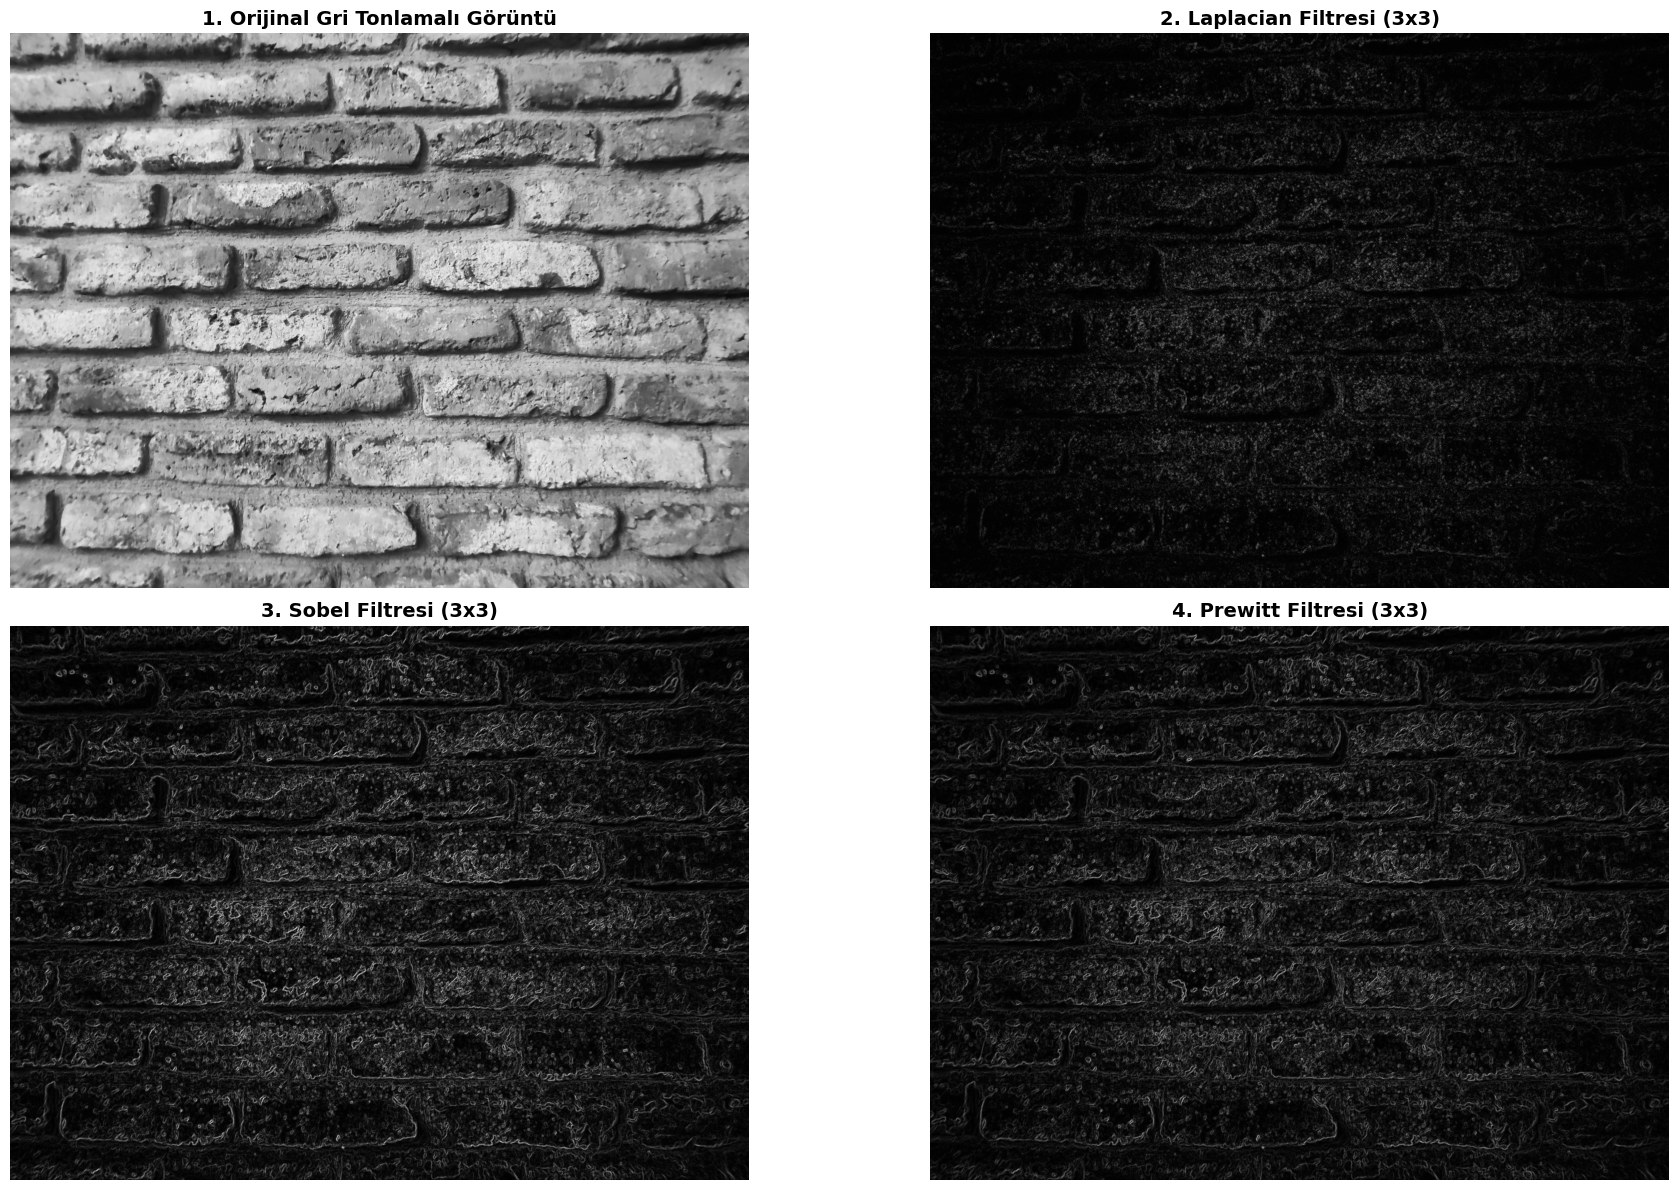

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img_path = 'tugla.jpg'
img_gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

if img_gray is None:
    print(f"Hata: '{img_path}' dosyası yüklenemedi. Test için yapay görsel oluşturuluyor...")
    img_gray = np.zeros((400, 400), dtype=np.uint8)
    cv2.putText(img_gray, 'TUGLA', (50, 220), cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 10, cv2.LINE_AA)


blurred_img = cv2.GaussianBlur(img_gray, (5, 5), 1.0)


laplacian_raw = cv2.Laplacian(blurred_img, cv2.CV_16S, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian_raw)

sobel_x = cv2.Sobel(blurred_img, cv2.CV_16S, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred_img, cv2.CV_16S, 0, 1, ksize=3)
sobel_abs_x = cv2.convertScaleAbs(sobel_x)
sobel_abs_y = cv2.convertScaleAbs(sobel_y)
sobel_combined = cv2.addWeighted(sobel_abs_x, 0.5, sobel_abs_y, 0.5, 0)

kernel_px = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
kernel_py = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
prewitt_x = cv2.filter2D(blurred_img, cv2.CV_16S, kernel_px)
prewitt_y = cv2.filter2D(blurred_img, cv2.CV_16S, kernel_py)
prewitt_abs_x = cv2.convertScaleAbs(prewitt_x)
prewitt_abs_y = cv2.convertScaleAbs(prewitt_y)
prewitt_combined = cv2.addWeighted(prewitt_abs_x, 0.5, prewitt_abs_y, 0.5, 0)


plt.figure(figsize=(20, 12))

plt.subplot(2, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('1. Orijinal Gri Tonlamalı Görüntü', fontsize=14, fontweight='bold')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(laplacian_abs, cmap='gray')
plt.title('2. Laplacian Filtresi (3x3)', fontsize=14, fontweight='bold')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sobel_combined, cmap='gray')
plt.title('3. Sobel Filtresi (3x3)', fontsize=14, fontweight='bold')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(prewitt_combined, cmap='gray')
plt.title('4. Prewitt Filtresi (3x3)', fontsize=14, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()